Finish the make your own neural network book/tutorial. Don’t skip the part of the tutorial that includes the MNIST dataset.

Create slides describing what you learned from the tutorial.

Be ready to share your code, and the results from the MNIST dataset classification exercise

Create your own number and classify it

Add what you want to learn to the class roster google sheet.


In [ ]:
# initialise the neural network
def __init__(self, inputnodes, hiddennodes, outputnodes,  learningrate):
    # set number of nodes in each input, hidden, output layer
    self.inodes = inputnodes
    self.hnodes = hiddennodes
    self.onodes = outputnodes
    # learning rate
    self.lr = learningrate
    pass

    # [1] tell number of input, hidden and output nodes
    input_nodes = 3
    hidden_nodes = 3
    output_nodes = 3
    # learning rate is 0.3
    learning_rate = 0.3
    # create instance of neural network 输入一个真正的具体神经网络
    n = neuralNetwork(input_nodes,hidden_nodes,output_nodes, learning_rate)
    # [2] link weight matrices, wih and who
    # weights inside the arrays are w_i_j, where link is from node i to node j in the next layer
    # w11 w21
    # w12 w22 etc
    self.wih = (numpy.random.rand(self.hnodes, self.inodes)- 0.5)
    self.who = (numpy.random.rand(self.onodes, self.hnodes)- 0.5)

In [ ]:
numpy.random.rand(5,2)-0.5

array([[ 0.1380519 , -0.22417697],
       [ 0.36086614,  0.43908078],
       [-0.40444288,  0.37224421],
       [-0.05951463, -0.43670119],
       [ 0.1871002 , -0.40863014]])

In [ ]:
import numpy
# scipy.special for the sigmoid function expit()
import scipy.special
# neural network class definition
class neuralNetwork:


    # initialise the neural network
    def __init__(self, inputnodes, hiddennodes, outputnodes, learningrate):
        # set number of nodes in each input, hidden, output layer
        self.inodes = inputnodes
        self.hnodes = hiddennodes
        self.onodes = outputnodes

        # link weight matrices, wih and who
        # weights inside the arrays are w_i_j, where link is from node i to node j in the next layer
        # w11 w21
        # w12 w22 etc
        self.wih = numpy.random.normal(0.0, pow(self.inodes, -0.5), (self.hnodes, self.inodes))
        self.who = numpy.random.normal(0.0, pow(self.hnodes, -0.5), (self.onodes, self.hnodes))

        # learning rate
        self.lr = learningrate

        # activation function is the sigmoid function
        self.activation_function = lambda x: scipy.special.expit(x)

        pass


    # train the neural network
    def train(self, inputs_list, targets_list):
        # convert inputs list to 2d array
        inputs = numpy.array(inputs_list, ndmin=2).T
        targets = numpy.array(targets_list, ndmin=2).T

        # calculate signals into hidden layer
        hidden_inputs = numpy.dot(self.wih, inputs)
        # calculate the signals emerging from hidden layer
        hidden_outputs = self.activation_function(hidden_inputs)

        # calculate signals into final output layer
        final_inputs = numpy.dot(self.who, hidden_outputs)
        # calculate the signals emerging from final output layer
        final_outputs = self.activation_function(final_inputs)

        # output layer error is the (target - actual)
        output_errors = targets - final_outputs
        # hidden layer error is the output_errors, split by weights, recombined at hidden nodes
        hidden_errors = numpy.dot(self.who.T, output_errors)

        # update the weights for the links between the hidden and output layers
        self.who += self.lr * numpy.dot((output_errors * final_outputs * (1.0 - final_outputs)), numpy.transpose(hidden_outputs))

        # update the weights for the links between the input and hidden layers
        self.wih += self.lr * numpy.dot((hidden_errors * hidden_outputs * (1.0 - hidden_outputs)), numpy.transpose(inputs))

        pass


    # query the neural network
    def query(self, inputs_list):
        # convert inputs list to 2d array
        inputs = numpy.array(inputs_list, ndmin=2).T

        # calculate signals into hidden layer
        hidden_inputs = numpy.dot(self.wih, inputs)
        # calculate the signals emerging from hidden layer
        hidden_outputs = self.activation_function(hidden_inputs)

        # calculate signals into final output layer
        final_inputs = numpy.dot(self.who, hidden_outputs)
        # calculate the signals emerging from final output layer
        final_outputs = self.activation_function(final_inputs)

        return final_outputs

# number of input, hidden and output nodes
input_nodes = 3
hidden_nodes = 3
output_nodes = 3

# learning rate is 0.3
learning_rate = 0.3

# create instance of neural network
n = neuralNetwork(input_nodes,hidden_nodes,output_nodes, learning_rate)
# test query (doesn't mean anything useful yet)
n.query([1.0, 0.5, -1.5])

array([[0.53241703],
       [0.45295717],
       [0.58892778]])

In [ ]:
from PIL import Image

for i in range(10):
    img = Image.open(f"/Users/Qquan/my_{i}.png")
    img = img.convert("L")
    img = img.resize((28, 28))
    img.save(f"/Users/Qquan/my_{i}_28x28.png")

print("convert done")

convert done


In [ ]:
import numpy
import imageio.v3
import glob

# Create our own image test dataset
our_own_dataset = []

for image_file_name in glob.glob('/Users/Qquan/my_?_28x28.png'):

    # Get the correct answer from the filename
    # For example: my_7_28x28.png -> label = 7
    label = int(image_file_name.split("my_")[1].split("_")[0])

    print("loading ...", image_file_name)

    # Read the grayscale image
    img_array = imageio.v3.imread(image_file_name, mode='F')

    # 28×28 -> 784, and invert black and white
    img_data = 255.0 - img_array.reshape(784)

    # Scale to 0.01 ~ 1.00
    img_data = (img_data / 255.0 * 0.99) + 0.01

    # Check the data range
    print("label =", label)
    print("min =", numpy.min(img_data))
    print("max =", numpy.max(img_data))

    # Combine the true label + 784 pixels into one record
    record = numpy.append(label, img_data)

    # Add it to our own test dataset
    our_own_dataset.append(record)

loading ... /Users/Qquan/my_7_28x28.png
label = 7
min = 0.18082353
max = 0.73211765
loading ... /Users/Qquan/my_1_28x28.png
label = 1
min = 0.15752943
max = 0.7864706
loading ... /Users/Qquan/my_6_28x28.png
label = 6
min = 0.12258823
max = 0.73211765
loading ... /Users/Qquan/my_0_28x28.png
label = 0
min = 0.19635296
max = 0.80976474
loading ... /Users/Qquan/my_8_28x28.png
label = 8
min = 0.11870588
max = 0.79811764
loading ... /Users/Qquan/my_5_28x28.png
label = 5
min = 0.18082353
max = 0.8369412
loading ... /Users/Qquan/my_3_28x28.png
label = 3
min = 0.13423531
max = 0.7942353
loading ... /Users/Qquan/my_9_28x28.png
label = 9
min = 0.16529413
max = 0.79035294
loading ... /Users/Qquan/my_4_28x28.png
label = 4
min = 0.14588237
max = 0.81752944
loading ... /Users/Qquan/my_2_28x28.png
label = 2
min = 0.14588237
max = 0.7942353


0 -> 0
1 -> 1
2 -> 2
3 -> 3
4 -> 4
5 -> 5
6 -> 6
7 -> 7
8 -> 8
9 -> 9
correct label = 7


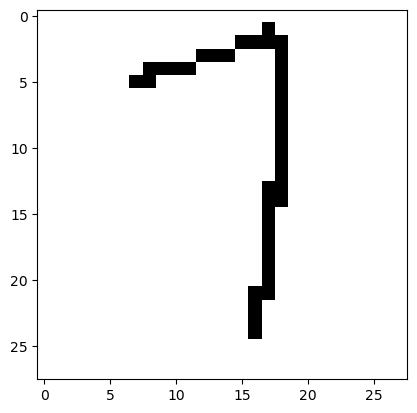

In [ ]:
import matplotlib.pyplot as plt

#reorder
our_own_dataset.sort(key=lambda record: int(record[0]))
for i, record in enumerate(our_own_dataset):
    print(i, "->", int(record[0]))

record = our_own_dataset[7]

label = int(record[0])
image_data = record[1:].reshape((28, 28))

print("correct label =", label)

plt.imshow(image_data, cmap='Greys', interpolation='None')
plt.show()

In [ ]:
#改node
input_nodes = 784
hidden_nodes = 200
output_nodes = 10
learning_rate = 0.1

n = neuralNetwork(
    input_nodes,
    hidden_nodes,
    output_nodes,
    learning_rate
)
print(n.wih.shape)
print(n.who.shape)

(200, 784)
(10, 200)


In [ ]:
#MNIST training
training_data_file = open(
    "/Users/Qquan/mnist_dataset/mnist_train.csv",
    "r"
)
training_data_list = training_data_file.readlines()
training_data_file.close()

epochs = 5
for e in range(epochs):
    for record in training_data_list:

        all_values = record.split(',')

        inputs = (
            numpy.asfarray(all_values[1:]) / 255.0 * 0.99
        ) + 0.01

        targets = numpy.zeros(output_nodes) + 0.01
        targets[int(all_values[0])] = 0.99

        n.train(inputs, targets)
print("finish")

finish


In [ ]:
import numpy as np
from PIL import Image

our_own_dataset = []

for i in range(10):

    img = Image.open(f"/Users/Qquan/my_{i}_28x28.png").convert("L")
    img_array = np.asarray(img)

    # 二值化
    threshold = 128
    binary = np.where(img_array < threshold, 0, 255)

    # 反色 + reshape
    img_data = 255.0 - binary.reshape(784)

    # scaling
    img_data = (img_data / 255.0 * 0.99) + 0.01

    record = np.append(i, img_data)
    our_own_dataset.append(record)

    print(
        i,
        "min =", img_data.min(),
        "max =", img_data.max()
    )

0 min = 0.01 max = 1.0
1 min = 0.01 max = 1.0
2 min = 0.01 max = 1.0
3 min = 0.01 max = 1.0
4 min = 0.01 max = 1.0
5 min = 0.01 max = 1.0
6 min = 0.01 max = 1.0
7 min = 0.01 max = 1.0
8 min = 0.01 max = 1.0
9 min = 0.01 max = 1.0


In [ ]:
scorecard = []

for record in our_own_dataset:

    # correct number
    correct_label = int(record[0])

    # 784_image
    inputs = record[1:]

    # predict
    outputs = n.query(inputs)

    #
    label = numpy.argmax(outputs)

    print("correct =", correct_label,
          "| network says =", label)

    if label == correct_label:
        print("match!")
        scorecard.append(1)
    else:
        print("NO MATCH!")
        scorecard.append(0)

    print()

correct = 0 | network says = 3
NO MATCH!

correct = 1 | network says = 1
match!

correct = 2 | network says = 2
match!

correct = 3 | network says = 3
match!

correct = 4 | network says = 4
match!

correct = 5 | network says = 1
NO MATCH!

correct = 6 | network says = 6
match!

correct = 7 | network says = 2
NO MATCH!

correct = 8 | network says = 8
match!

correct = 9 | network says = 7
NO MATCH!

